Single allele groupped structue models.

In [135]:
import numpy as np

import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [136]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/single_allele_balanced_data_base_model/" #!CHANGE for bwv!

In [137]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*03:01',
 'HLA-A*02:01',
 'HLA-DPA1*01:03-DPB1*04:01',
 'HLA-DRB1*04:01',
 'HLA-B*07:02',
 'HLA-B*27:05',
 'HLA-DRB1*01:01',
 'HLA-A*01:01']

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [138]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
# ALLELES = sorted([ 'HLA-A*03:01'])

ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [15]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]

In [139]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*01:03-DPB1*04:01
Length 9: HLA-DPA1*01:03-DPB1*04:01 - 14 
Length 10: HLA-DPA1*01:03-DPB1*04:01 - 68 
Length 11: HLA-DPA1*01:03-DPB1*04:01 - 288 
Length 12: HLA-DPA1*01:03-DPB1*04:01 - 725 
Length 13: HLA-DPA1*01:03-DPB1*04:01 - 1366 
Length 14: HLA-DPA1*01:03-DPB1*04:01 - 1802 
Length 15: HLA-DPA1*01:03-DPB1*04:01 - 2260 
Length 16: HLA-DPA1*01:03-DPB1*04:01 - 1580 
Length 17: HLA-DPA1*01:03-DPB1*04:01 - 1160 
Length 18: HLA-DPA1*01:03-DPB1*04:01 - 756 
Length 19: HLA-DPA1*01:03-DPB1*04:01 - 460 
Length 20: HLA-DPA1*01:03-DPB1*04:01 - 299 
Length 21: HLA-DPA1*01:03-DPB1*04:01 - 165 
Length 22: HLA-DPA1*01:03-DPB1*04:01 - 108 
Length 23: HLA-DPA1*01:03-DPB1*04:01 - 74 
Length 24: HLA-DPA1*01:03-DPB1*04:01 - 60 
Length 25: HLA-DPA1*01:03-DPB1*04:01 - 45 
Length 26: HLA-DPA1*01:03-DPB1*04:01 - 25 
Length 27: HLA-DPA1*01:03-DPB1*04:01 - 26 
Length 28: HLA-DPA1*01:03-DPB1*04:01 - 20 
Length 29: HLA-DPA1*01:03-DPB1*04:01 - 16 
Length 30: HLA-DPA1*01:03-DPB1*04:01 - 12 
HLA-DRB1*01:

In [140]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [111]:
import logomaker
peptides = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][13]


In [112]:
selected = [peptide for peptide in peptides if peptide[0] in {'L', 'Y', 'F', 'W'} and peptide[3] not in {'L', 'Y', 'F', 'W'} ]

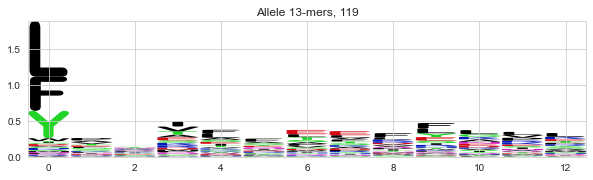

In [9]:
make_logo_for_data(selected, "13-mers")

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [141]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [142]:
count_df_train.index.levels

FrozenList([['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01'], [0, 1, 2, 3, 4], [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30]])

## 2.3 Weights for data based on counts

In [143]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 8924
Weights for lentgh 13 are {'HLA-DPA1*01:03-DPB1*04:01': 6.53294289897511}
Weights for lentgh 14 are {'HLA-DPA1*01:03-DPB1*04:01': 4.952275249722531}
Weights for lentgh 15 are {'HLA-DPA1*01:03-DPB1*04:01': 3.9486725663716813}
Weights for lentgh 16 are {'HLA-DPA1*01:03-DPB1*04:01': 5.648101265822785}
Weights for lentgh 17 are {'HLA-DPA1*01:03-DPB1*04:01': 7.6931034482758625}
Weights for lentgh 18 are {'HLA-DPA1*01:03-DPB1*04:01': 11.804232804232804}
Total data length for split 1 is 8924
Weights for lentgh 13 are {'HLA-DPA1*01:03-DPB1*04:01': 6.53294289897511}
Weights for lentgh 14 are {'HLA-DPA1*01:03-DPB1*04:01': 4.952275249722531}
Weights for lentgh 15 are {'HLA-DPA1*01:03-DPB1*04:01': 3.9486725663716813}
Weights for lentgh 16 are {'HLA-DPA1*01:03-DPB1*04:01': 5.644528779253637}
Weights for lentgh 17 are {'HLA-DPA1*01:03-DPB1*04:01': 7.6931034482758625}
Weights for lentgh 18 are {'HLA-DPA1*01:03-DPB1*04:01': 11.804232804232804}
Total data length fo

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [144]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [145]:
stop_threshold = 0
cutoff = 0.0005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

56.45583333333334

### 2.2.2 Prepare  initial grouped structure models

In [146]:
# Training params
algorithm = 'baum-welch'

params = dict()


params['st'] = 25
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 20
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0.25
params['distribution_inertia'] = 0
params['groups'] = 5
params['states_per_group'] = 5
params['use_pseudocount'] = True

assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))



In [147]:
cycle_pseudocount = 80000
model = init_grouped_structure_model_joiners_and_cycles(states_per_group=int(params['states_per_group']), number_of_groups=params['groups'], freeze_distr=True, CYCLE_PSEUDOCOUNT=cycle_pseudocount)


grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 21.0, normalized to 1.0
grouped_model : s001 summed to 21.0, normalized to 1.0
grouped_model : s002 summed to 21.0, normalized to 1.0
grouped_model : s003 summed to 21.0, normalized to 1.0
grouped_model : s004 summed to 21.0, normalized to 1.0
grouped_model : s005 summed to 21.0, normalized to 1.0
grouped_model : s006 summed to 21.0, normalized to 1.0
grouped_model : s007 summed to 21.0, normalized to 1.0
grouped_model : s008 summed to 21.0, normalized to 1.0
grouped_model : s009 summed to 21.0, normalized to 1.0
grouped_model : s010 summed to 21.0, normalized to 1.0
grouped_model : s011 summed to 21.0, normalized to 1.0
grouped_model : s012 summed to 21.0, normalized to 1.0
grouped_model : s013 summed to 21.0, normalized to 1.0
grouped_model : s014 summed to 21.0, normalized to 1.0
grouped_model : s015 summed to 21.0, normalized to 1.0
grouped_model : s016 summed to 21.0, normalized to 

In [148]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [149]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False)

In [150]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=31 |E|=218

In [151]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [152]:
ten_mer = allele_peptides[12]
ten_mer, len(ten_mer)

('IHFHAESFLYRNG', 13)

In [153]:
prob, path = model.viterbi(ten_mer)

In [154]:
[item[0] for item in path]

[29, 27, 25, 0, 6, 10, 15, 23, 26, 28, 28, 28, 28, 28, 30]

In [155]:
sixteen_mer = allele_peptides[8000]
sixteen_mer, len(sixteen_mer)

('VSHLIATEYLNYEDGKF', 17)

In [156]:
pd.DataFrame(model.forward_backward(sixteen_mer)[1])

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-0.132527,-inf,-2.086502,-inf
1,-2.055687,-4.274551,-1.329571,-1.456027,-1.443056,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-2.343832,-inf,-3.569803,-inf
2,-1.720732,-3.611979,-1.581585,-1.960224,-1.932166,-3.922651,-2.204405,-2.802569,-5.502832,-2.528717,...,-inf,-inf,-inf,-inf,-inf,-inf,-3.783187,-inf,-5.219257,-inf
3,-3.075063,-6.105711,-1.831293,-2.103813,-2.466135,-2.448932,-2.614282,-2.321011,-2.263789,-1.920697,...,-inf,-inf,-inf,-inf,-inf,-inf,-5.807767,-inf,-6.029284,-inf
4,-2.553233,-4.267693,-5.214378,-4.489292,-3.044120,-2.791191,-4.443235,-1.439082,-1.664497,-1.923072,...,-5.656718,-inf,-inf,-inf,-inf,-inf,-6.453668,-inf,-7.091098,-inf
5,-5.218939,-3.439581,-4.404795,-5.149964,-4.098450,-3.306247,-1.693815,-3.445644,-2.456411,-2.019378,...,-7.305419,-7.216501,-6.882719,-8.904993,-7.024330,-6.921860,-7.214372,-inf,-9.245446,-inf
6,-7.780439,-5.844999,-4.017611,-4.524808,-4.936415,-2.730522,-6.986034,-2.250917,-3.852734,-3.216000,...,-5.566284,-6.198303,-5.343972,-5.944514,-6.087259,-7.043517,-9.375279,-14.806969,-11.351167,-inf
7,-4.513117,-4.448975,-8.801515,-6.343858,-4.827236,-7.507524,-3.206418,-4.508850,-3.758634,-4.239094,...,-2.514289,-6.813368,-5.244420,-4.833292,-5.538853,-3.852690,-11.478401,-13.931618,-13.475831,-14.806969
8,-6.087158,-5.220736,-4.992230,-5.450630,-5.492828,-5.411036,-4.623036,-4.901587,-5.326259,-3.909950,...,-3.077969,-5.482743,-3.457222,-2.967900,-3.216819,-3.626597,-13.754764,-11.411019,-14.888841,-13.583276
9,-6.643312,-10.186135,-5.773875,-5.984314,-6.179129,-5.312786,-5.386044,-4.748132,-4.894185,-4.630644,...,-4.012787,-2.610669,-2.760283,-4.498074,-2.786510,-2.919333,-15.077199,-8.725379,-16.650955,-11.303134


In [157]:
pd.DataFrame(model.forward_backward(ten_mer)[1])

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-0.727139,-inf,-0.660273,-inf
1,-2.415015,-4.443236,-1.646844,-2.317157,-2.397384,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-0.785305,-inf,-2.801325,-inf
2,-1.516353,-1.764825,-4.100985,-2.149840,-1.750622,-2.575879,-4.133420,-2.833184,-2.769808,-3.568312,...,-inf,-inf,-inf,-inf,-inf,-inf,-2.817853,-inf,-6.912255,-inf
3,-2.494795,-4.604271,-1.653189,-2.307740,-2.537221,-3.455527,-1.774674,-2.294527,-5.051544,-1.993192,...,-inf,-inf,-inf,-inf,-inf,-inf,-7.074320,-inf,-8.811954,-inf
4,-3.748892,-2.388554,-3.369272,-3.963119,-2.773643,-3.197928,-2.139697,-3.134944,-2.300385,-2.014693,...,-7.952026,-inf,-inf,-inf,-inf,-inf,-8.816521,-inf,-14.203121,-inf
5,-2.982953,-3.107847,-6.707519,-4.476845,-3.236055,-6.386268,-2.470003,-3.123780,-2.797651,-3.183508,...,-3.404119,-8.760874,-6.747913,-6.380319,-7.350724,-5.614166,-14.230202,-inf,-17.825531,-inf
6,-5.785094,-8.087113,-4.534503,-4.857233,-5.082072,-2.774630,-2.771202,-2.670929,-5.534096,-3.163337,...,-2.279819,-3.989106,-5.090195,-3.965140,-3.592392,-4.061476,-17.825531,-9.897118,-inf,-inf
7,-7.338444,-7.680815,-10.097503,-8.176579,-7.727657,-3.762649,-5.076468,-3.935099,-3.800709,-4.521331,...,-3.194649,-2.729427,-3.237311,-2.809031,-4.288865,-3.932940,-inf,-5.560374,-inf,-9.897118
8,-inf,-inf,-inf,-inf,-inf,-6.664014,-6.524903,-6.146512,-6.304799,-5.723600,...,-3.877701,-2.245962,-2.589128,-4.394748,-2.438674,-2.622143,-inf,-5.046588,-inf,-5.547380
9,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-3.254774,-4.031413,-2.133614,-1.500977,-1.844082,-2.082650,-inf,-4.768869,-inf,-4.572810


In [158]:
state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
assert np.isclose(sum(state_sums), len(state_sums))

In [159]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles(states_per_group=int(params['states_per_group']), number_of_groups=params['groups'], CYCLE_PSEUDOCOUNT=80000, freeze_distr=True)

            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 21.0, normalized to 1.0
grouped_model : s001 summed to 21.0, normalized to 1.0
grouped_model : s002 summed to 21.0, normalized to 1.0
grouped_model : s003 summed to 21.0, normalized to 1.0
grouped_model : s004 summed to 21.0, normalized to 1.0
grouped_model : s005 summed to 21.0, normalized to 1.0
grouped_model : s006 summed to 21.0, normalized to 1.0
grouped_model : s007 summed to 21.0, normalized to 1.0
grouped_model : s008 summed to 21.0, normalized to 1.0
grouped_model : s009 summed to 21.0, normalized to 1.0
grouped_model : s010 summed to 21.0, normalized to 1.0
grouped_model : s011 summed to 21.0, normalized to 1.0
grouped_model : s012 summed to 21.0, normalized to 1.0
grouped_model : s013 summed to 21.0, normalized to 1.0
grouped_model : s014 summed to 21.0, normalized to 1.0
grouped_model : s015 summed to 21.0, normalized to 1.0
grouped_model : s016 summed to 21.0, normalized to 

In [160]:
cycle_state = prepared_model.states[52]
start = prepared_model.states[53]

IndexError: list index out of range

In [161]:
prepared_model.graph.edges()[cycle_state, cycle_state]

KeyError: {
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.00031322590553366393,
                "C" : 0.061920510035630365,
                "D" : 0.030979626962700978,
                "E" : 0.037540489260065535,
                "F" : 0.05507011545935503,
                "G" : 0.07884677305039309,
                "H" : 0.03341274559093297,
                "I" : 0.09982302233344154,
                "K" : 0.10192655886528332,
                "L" : 0.07534858384246275,
                "M" : 0.06199010281633185,
                "N" : 0.04303240827017443,
                "P" : 0.008669422570877463,
                "Q" : 0.04249150987589864,
                "R" : 0.06531164032561289,
                "S" : 0.0697425235299144,
                "T" : 0.04443909295211443,
                "V" : 0.08097118109927146,
                "W" : 0

In [162]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01']

model

In [163]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'])
        
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)
        break


run 0
split 0
train size 8924
Shuffling for fairness 
Simple training: Train Length 8924, init_batch_size None
Use pseudocount is True
[1] Improvement: 256175.2550039296	Time (s): 6.253
[2] Improvement: 15609.009513681754	Time (s): 4.32
[3] Improvement: 3319.882987833116	Time (s): 7.158
[4] Improvement: 1182.2392700891942	Time (s): 4.058
[5] Improvement: 690.3775839074515	Time (s): 5.216
[6] Improvement: 535.1942814970389	Time (s): 4.851
[7] Improvement: 467.7460990739055	Time (s): 7.701
[8] Improvement: 438.102575911209	Time (s): 7.72
[9] Improvement: 434.897249863483	Time (s): 10.47
[10] Improvement: 454.61027295840904	Time (s): 10.71
[11] Improvement: 496.36556317890063	Time (s): 6.14
[12] Improvement: 561.3103707460687	Time (s): 6.123
[13] Improvement: 652.6425324548036	Time (s): 4.562
[14] Improvement: 775.6804353827611	Time (s): 6.144
[15] Improvement: 937.8242238047533	Time (s): 5.464
[16] Improvement: 1148.0733595159836	Time (s): 5.104
[17] Improvement: 1415.3235267931595	Time 

In [164]:
from hmm_visualization_methods import *

In [165]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
Wall time: 2.35 s


In [166]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)
    print(i)

0
1
Wall time: 24.4 s


In [167]:
from hmm_visualization_methods import *
per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01-0) (Delete zero edges)
Converting graph for model (0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)


In [134]:
TARGET_PATH_TO_RESULTS

'experiment_results/single_allele_balanced_data_base_model/'

In [ ]:
model

In [49]:
cycle_state = model.states[27]
start = model.states[29]

In [50]:
model.graph.edges()[cycle_state, cycle_state]

{'probability': -1.2327600919633284, 'pseudocount': 8000, 'group': None}